In [451]:
import numpy as np

In [452]:
from data import load_mnist

(xtrain, ytrain), (xval, yval), num_cls = load_mnist()

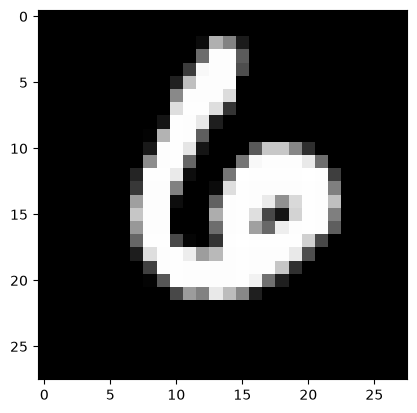

In [453]:
import matplotlib.pyplot as plt

img = xtrain[44,:].reshape(28,28) # First image in the training set.
plt.imshow(img,cmap='gray')
plt.show() # Show the image

In [454]:
print("Shape:", xtrain.shape)
print("Minimum:", np.min(xtrain))
print("Maximum:", np.max(xtrain))
print("Data type:", xtrain.dtype)

Shape: (55000, 784)
Minimum: 0
Maximum: 255
Data type: uint8


In [455]:
xtrain = xtrain.astype(np.float32) / 255.0
xval = xval.astype(np.float32) / 255.0

In [456]:
def softmax(o):
    exp_o = np.exp(o - np.max(o))
    return exp_o / np.sum(exp_o)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def derivative_sigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

def cross_entropy(y, t):
    return -np.sum(t * np.log(y))


In [457]:
def forward(x, w, v, b, c):
    k = x @ w + b
    h = sigmoid(k)
    o = h @ v + c
    y = softmax(o)
    
    return k, h, o, y

In [458]:
def backpropagation(x, t, k, h, y, v):
    dL_do = y - t
    dL_dh = v @ dL_do
    dL_dk = dL_dh * derivative_sigmoid(k)

    dL_dw = np.outer(x, dL_dk)
    dL_dv = np.outer(h, dL_do)
    dL_db = dL_dk
    dL_dc = dL_do
    return dL_dw, dL_dv, dL_db, dL_dc

In [459]:
np.random.seed(42)

w = np.random.normal(0, 0.5, size=(784, 300))
v = np.random.normal(0, 0.5, size=(300, 10))
b = np.zeros(300)
c = np.zeros(10)

In [460]:
learning_rate = 0.003
loss_history = []

# Randomly select 10,000 training examples without duplicates within this epoch.
for epoch in range(30):
    epoch_loss = 0
    indices = np.random.choice(len(xtrain), size=10000, replace=False)
    for index in indices:
        x = xtrain[index]

        label = int(ytrain[index])
        t = np.zeros(10)
        t[label] = 1

        k, h, o, y = forward(x, w, v, b, c)
        loss = cross_entropy(y, t)

        dL_dw, dL_dv, dL_db, dL_dc = backpropagation(x, t, k, h, y, v)

        w -= learning_rate * dL_dw 
        v -= learning_rate * dL_dv
        b -= learning_rate * dL_db
        c -= learning_rate * dL_dc
        
        epoch_loss += loss

    average_loss = epoch_loss / len(indices)
    loss_history.append(average_loss)

    print(f"Epoch {epoch + 1}: Loss = {average_loss:.4f}")




Epoch 1: Loss = 1.2383
Epoch 2: Loss = 0.5618
Epoch 3: Loss = 0.4515
Epoch 4: Loss = 0.3929
Epoch 5: Loss = 0.3633
Epoch 6: Loss = 0.3416
Epoch 7: Loss = 0.3136
Epoch 8: Loss = 0.2945
Epoch 9: Loss = 0.2863
Epoch 10: Loss = 0.2573
Epoch 11: Loss = 0.2530
Epoch 12: Loss = 0.2358
Epoch 13: Loss = 0.2492
Epoch 14: Loss = 0.2471
Epoch 15: Loss = 0.2356
Epoch 16: Loss = 0.2202
Epoch 17: Loss = 0.2123
Epoch 18: Loss = 0.1894
Epoch 19: Loss = 0.2127
Epoch 20: Loss = 0.1986
Epoch 21: Loss = 0.1952
Epoch 22: Loss = 0.1992
Epoch 23: Loss = 0.1778
Epoch 24: Loss = 0.1880
Epoch 25: Loss = 0.1787
Epoch 26: Loss = 0.1756
Epoch 27: Loss = 0.1587
Epoch 28: Loss = 0.1700
Epoch 29: Loss = 0.1725
Epoch 30: Loss = 0.1779


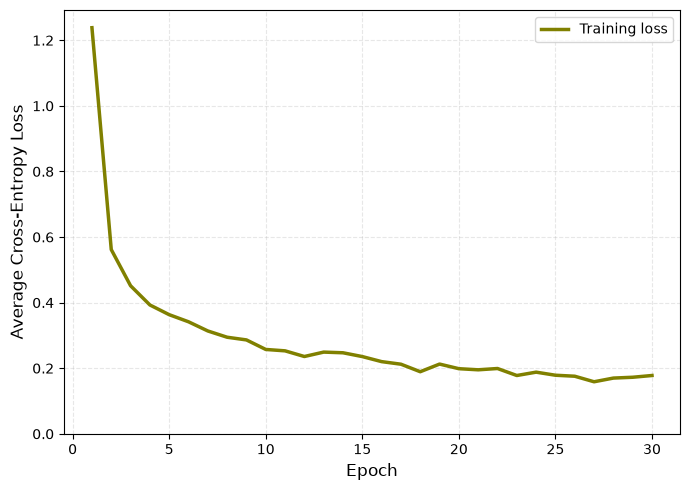

In [461]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

epochs = range(1, len(loss_history) + 1)

ax.plot(epochs, loss_history,
        color="olive",
        linewidth=2.5,
        label="Training loss")

ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Average Cross-Entropy Loss", fontsize=12)


ax.set_ylim(bottom=0)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [462]:
correct = 0

for index in range(len(xval)):
    x = xval[index]
    label = int(yval[index])

    k, h, o, y = forward(x, w, v, b, c)

    prediction = np.argmax(y)

    if prediction == label:
        correct += 1

accuracy = correct / len(xval)

print(f"Validation accuracy: {accuracy * 100:.2f}")

Validation accuracy: 94.00


In [463]:
def softmax_batch(o):
    exp_o = np.exp(o - np.max(o, axis=1, keepdims=True))
    return exp_o / np.sum(exp_o, axis=1, keepdims=True)

In [464]:
def forward_batch(x, w, v, b, c):
    k = x @ w + b
    h = sigmoid(k)
    o = h @ v + c
    y = softmax_batch(o)
    return k, h, o, y


In [465]:
def backpropagation_batch(x, t, k, h, y, v):
    batch_size = len(x)

    dL_do = (y - t) / batch_size
    dL_dh = dL_do @ v.T
    dL_dk = dL_dh * derivative_sigmoid(k)

    dL_dw = x.T @ dL_dk
    dL_dv = h.T @ dL_do
    dL_db = np.sum(dL_dk, axis=0)
    dL_dc = np.sum(dL_do, axis=0)

    return dL_dw, dL_dv, dL_db, dL_dc

In [466]:
(xtrain, ytrain), (xval, yval), num_cls = load_mnist(final=False)

In [467]:
xtrain = xtrain.astype(np.float32) / 255.0
xval = xval.astype(np.float32) / 255.0

In [468]:
np.random.seed(42)

w = np.random.normal(0, 0.5, (784, 200))
v = np.random.normal(0, 0.5, (200, 10))

b = np.zeros(200)
c = np.zeros(10)

In [469]:
np.random.seed(42)

w = np.random.normal(0, 0.05, (784, 300))
v = np.random.normal(0, 0.05, (300, 10))

b = np.zeros(300)
c = np.zeros(10)

batch_size = 32
epochs = 100
learning_rate = 0.05

train_loss_history = []
val_loss_history = []
val_accuracy_history = []

for epoch in range(epochs):
    epoch_loss = 0
    indices = np.random.permutation(len(xtrain))

    for start in range(0, len(xtrain), batch_size):
        batch_indices = indices[start:start + batch_size]
        x_batch = xtrain[batch_indices]
        y_batch = ytrain[batch_indices]

        labels = y_batch
    
        t_batch = np.zeros((len(labels), 10))
        for i in range(len(labels)):
            t_batch[i, int(labels[i])] = 1

        k, h, o, y = forward_batch(x_batch, w, v, b, c)

        loss = -np.mean(np.sum(t_batch * np.log(y), axis=1))
        epoch_loss += loss * len(x_batch)

        dL_dw, dL_dv, dL_db, dL_dc = backpropagation_batch(x_batch, t_batch, k, h, y, v)

        w -= learning_rate * dL_dw
        v -= learning_rate * dL_dv
        b -= learning_rate * dL_db
        c -= learning_rate * dL_dc
    
    average_loss = epoch_loss / len(xtrain)
    train_loss_history.append(average_loss)

    val_loss_sum = 0
    val_correct = 0
    for start in range(0, len(xval), batch_size):
        x_batch = xval[start:start + batch_size]
        labels = yval[start:start + batch_size]

        t_batch = np.zeros((len(labels), 10))
        for i in range(len(labels)):
            t_batch[i, int(labels[i])] = 1

        k, h, o, y = forward_batch(x_batch, w, v, b, c)
        
        predictions = np.argmax(y, axis=1)
        val_correct += np.sum(predictions == labels)

        loss = -np.mean(np.sum(t_batch * np.log(y), axis=1))
        val_loss_sum += loss * len(labels)


    val_loss = val_loss_sum / len(xval)
    val_loss_history.append(val_loss)

    val_accuracy = val_correct / len(xval)
    val_accuracy_history.append(val_accuracy)
    max_accuracy = 0
    if max_accuracy < val_accuracy:
        max_accuracy = val_accuracy
        max_epoch = epoch
print(
    f"{max_epoch}:{max_accuracy:.2%}")



99:97.66%


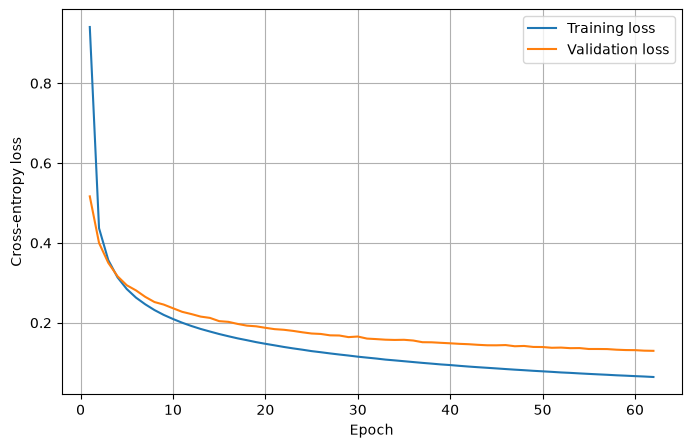

In [391]:

epochs = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_history, label="Training loss")
plt.plot(epochs, val_loss_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(True)
plt.show()

In [396]:
all_train_losses = []

for run in range(3):
    np.random.seed(42 + run)

    w = np.random.normal(0, 0.05, (784, 300))
    v = np.random.normal(0, 0.05, (300, 10))
    b = np.zeros(300)
    c = np.zeros(10)

    train_loss_history = []

    batch_size = 32
    epochs = 5
    learning_rate = 0.003

    train_loss_history = []
    val_loss_history = []


    for epoch in range(epochs):
        epoch_loss = 0
        
        for start in range(0, len(xtrain), batch_size):
            x_batch = xtrain[start:start + batch_size]
            y_batch = ytrain[start:start + batch_size]

            labels = y_batch
        
            t_batch = np.zeros((len(labels), 10))
            for i in range(len(labels)):
                t_batch[i, int(labels[i])] = 1

            k, h, o, y = forward_batch(x_batch, w, v, b, c)

            loss = -np.mean(np.sum(t_batch * np.log(y), axis=1))
            epoch_loss += loss * len(x_batch)

            dL_dw, dL_dv, dL_db, dL_dc = backpropagation_batch(x_batch, t_batch, k, h, y, v)

            w -= learning_rate * dL_dw
            v -= learning_rate * dL_dv
            b -= learning_rate * dL_db
            c -= learning_rate * dL_dc
        
        average_loss = epoch_loss / len(xtrain)
        train_loss_history.append(average_loss)

        val_loss_sum = 0

        for start in range(0, len(xval), batch_size):
            x_batch = xval[start:start + batch_size]
            labels = yval[start:start + batch_size]

            t_batch = np.zeros((len(labels), 10))
            for i in range(len(labels)):
                t_batch[i, int(labels[i])] = 1

            k, h, o, y = forward_batch(x_batch, w, v, b, c)

            loss = -np.mean(np.sum(t_batch * np.log(y), axis=1))
            val_loss_sum += loss * len(labels)

        val_loss = val_loss_sum / len(xval)
        val_loss_history.append(val_loss)
        print(f"Epoch {epoch + 1}: Train = {average_loss:.4f}, Validation = {val_loss:.4f}")


    all_train_losses.append(train_loss_history)

Epoch 1: Train = 2.0841, Validation = 1.8519
Epoch 2: Train = 1.6180, Validation = 1.4008
Epoch 3: Train = 1.2232, Validation = 1.0790
Epoch 4: Train = 0.9669, Validation = 0.8818
Epoch 5: Train = 0.8093, Validation = 0.7579
Epoch 1: Train = 2.0756, Validation = 1.8405
Epoch 2: Train = 1.6108, Validation = 1.3975
Epoch 3: Train = 1.2198, Validation = 1.0758
Epoch 4: Train = 0.9609, Validation = 0.8759
Epoch 5: Train = 0.8008, Validation = 0.7505
Epoch 1: Train = 2.0582, Validation = 1.8291
Epoch 2: Train = 1.6000, Validation = 1.3886
Epoch 3: Train = 1.2137, Validation = 1.0720
Epoch 4: Train = 0.9603, Validation = 0.8761
Epoch 5: Train = 0.8035, Validation = 0.7526


In [400]:
losses = np.array(batch_loss_history)

mean_loss = np.mean(losses, axis=0)
std_loss = np.std(losses, axis=0)

print("Mean:", mean_loss)
print("Std:", std_loss)

Mean: 1.3270974703186058
Std: 0.47236435446409425


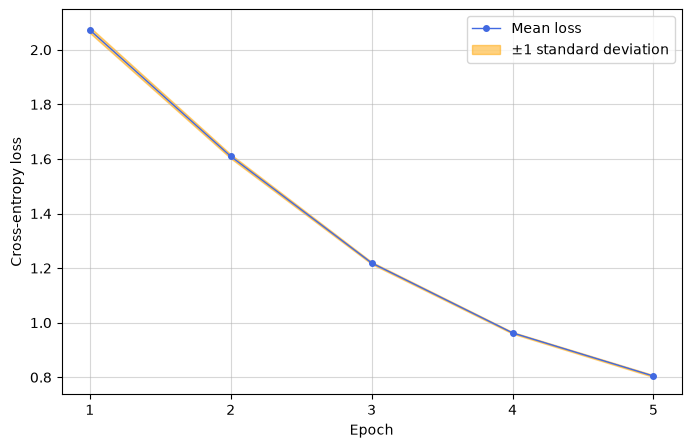

In [409]:
losses = np.array(all_train_losses)

mean_loss = losses.mean(axis=0)
std_loss = losses.std(axis=0)
epochs = np.arange(1, len(mean_loss) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, mean_loss,
    color="royalblue", linewidth=1,
    marker="o", markersize=4,
    label="Mean loss",
)
plt.fill_between(
    epochs,
    mean_loss - std_loss,
    mean_loss + std_loss,
    color="orange",
    alpha=0.5,
    label="±1 standard deviation",
)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Final

In [415]:
(xtrain, ytrain), (xtest, ytest), num_cls = load_mnist(final=True)

In [416]:
xtrain = xtrain.astype(np.float32) / 255.0
xtest = xtest.astype(np.float32) / 255.0

In [449]:
np.random.seed(42)

w = np.random.normal(0, 0.05, (784, 300))
v = np.random.normal(0, 0.05, (300, 10))
b = np.zeros(300)
c = np.zeros(10)


In [450]:
batch_size = 32
learning_rate = 0.05
epochs = 100

for epoch in range(epochs):

    indices = np.random.permutation(len(xtrain))

    for start in range(0, len(xtrain), batch_size):
        batch_indices = indices[start:start + batch_size]
        x_batch = xtrain[batch_indices]
        labels = ytrain[batch_indices]
        
        t_batch = np.zeros((len(labels), 10))
        for i in range(len(labels)):
            t_batch[i, int(labels[i])] = 1

        k, h, o, y = forward_batch(x_batch, w, v, b, c)
        
        dL_dw, dL_dv, dL_db, dL_dc = backpropagation_batch(
            x_batch, t_batch, k, h, y, v
        )

        w -= learning_rate * dL_dw
        v -= learning_rate * dL_dv
        b -= learning_rate * dL_db
        c -= learning_rate * dL_dc


# Evaluate the final model on the test set.
test_correct = 0

for start in range(0, len(xtest), batch_size):
    x_batch = xtest[start:start + batch_size]
    labels = ytest[start:start + batch_size]
    
    t_batch = np.zeros((len(labels), 10))
    for i in range(len(labels)):
        t_batch[i, int(labels[i])] = 1

    k, h, o, y = forward_batch(x_batch, w, v, b, c)
    
    predictions = np.argmax(y, axis=1)
    test_correct += np.sum(predictions == labels)

test_accuracy = test_correct / len(xtest)


print(f"Test accuracy: {test_accuracy:.2%}")


Test accuracy: 97.92%
